# ANALISIS DAN PEMBUKTIAN REPRESENTASI CITRA DIGITAL

**Nama:** Ade Ayu Wandira  
**NIM:** 24260007  
**Semester:** 5

In [2]:
# ==========================================
# 1. IMPORT LIBRARY
# ==========================================

from PIL import Image, ExifTags
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

## 1. Import Library

Library yang digunakan untuk membaca, mengolah, menampilkan, dan menganalisis citra digital:

- **PIL (Pillow)** → membaca dan mengolah file gambar.
- **ExifTags** → membaca metadata EXIF pada gambar.
- **NumPy** → mengolah citra dalam bentuk array atau susunan angka.
- **Matplotlib** → menampilkan dan memvisualisasikan citra.
- **Pandas** → menyusun dan menampilkan data dalam bentuk tabel.

In [3]:
# ==========================================
# 2. MEMBACA CITRA
# ==========================================

gambar = Image.open("foto/IMG_20240413_053916.jpg")

## 2. Membaca Citra

Kode berikut digunakan untuk membaca dan memuat file citra ke dalam Python agar dapat dianalisis pada tahap selanjutnya.

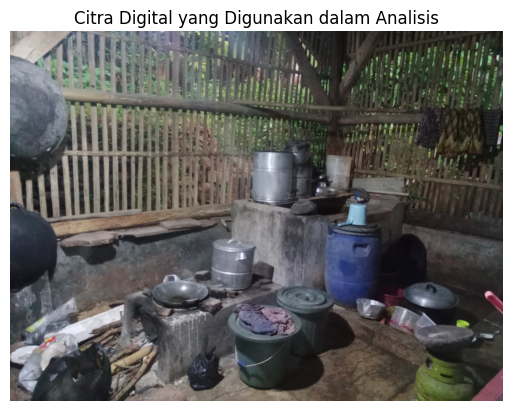

In [4]:
# ==========================================
# 3. MENAMPILKAN CITRA
# ==========================================

plt.imshow(gambar)
plt.title("Citra Digital yang Digunakan dalam Analisis")
plt.axis("off");

### 3. Menampilkan Citra

- `plt.imshow(gambar)` →  digunakan untuk menampilkan citra yang telah dibaca.
- `plt.title(...)` →  digunakan untuk memberikan judul pada tampilan citra.
- `plt.axis("off");` →  digunakan untuk menyembunyikan sumbu koordinat agar citra terlihat lebih jelas.

In [5]:
# ==========================================
# 4. INFORMASI GAMBAR
# ==========================================

# Membaca metadata EXIF
exif_data = gambar.getexif()

# Mengecek jumlah metadata yang ditemukan
print("Jumlah data EXIF:", len(exif_data))

# Menampilkan metadata dalam bentuk tabel
data_tabel = []

for tag_id, value in exif_data.items():
    tag_name = ExifTags.TAGS.get(tag_id, tag_id)
    data_tabel.append([tag_name, value])

# Informasi dasar gambar
print("\nInformasi Dasar Gambar")
print("Format gambar :", gambar.format)
print("Ukuran gambar :", gambar.size)
print("Mode warna    :", gambar.mode)
print("Jumlah kanal  :", len(gambar.getbands()))

pd.DataFrame(data_tabel, columns=["Metadata", "Nilai"])

Jumlah data EXIF: 14

Informasi Dasar Gambar
Format gambar : JPEG
Ukuran gambar : (3264, 2448)
Mode warna    : RGB
Jumlah kanal  : 3


,Metadata,Nilai
0,ImageWidth,3264
1,ImageLength,2448
2,GPSInfo,1103
3,ResolutionUnit,2
4,ExifOffset,346
5,ImageDescription,                               
6,Make,vivo                           
7,Model,V2252                          
8,Software,MediaTek Camera Application    
9,Orientation,1


## 4. Informasi Gambar

Pada tahap ini, dilakukan pemeriksaan informasi dasar gambar dan metadata EXIF yang tersimpan pada citra. Informasi dasar digunakan untuk mengetahui karakteristik file gambar, sedangkan metadata EXIF memberikan informasi tambahan mengenai gambar dan perangkat yang digunakan untuk mengambilnya.

**A. Informasi Dasar Gambar**

- `gambar.format` → mengetahui format file gambar. Hasilnya adalah **JPEG**.
- `gambar.size` → mengetahui ukuran gambar dalam urutan (lebar, tinggi). Hasilnya adalah **3264 × 2448 pixel**.
- `gambar.mode` → mengetahui mode warna gambar. Hasilnya adalah **RGB**, yang berarti gambar menggunakan kanal Red (R), Green (G), dan Blue (B).
- `gambar.getbands()` → mengetahui kanal warna yang digunakan. Hasilnya terdiri dari **3 kanal**, yaitu R, G, dan B.

**B. Metadata EXIF**

- `gambar.getexif()` → mengambil metadata EXIF yang tersimpan pada gambar.
- `len(exif_data)` → menghitung jumlah data EXIF yang ditemukan. Hasilnya adalah **14 data**.
- `exif_data.items()` → mengakses setiap ID metadata beserta nilainya.
- `ExifTags.TAGS.get(tag_id, tag_id)` → menerjemahkan ID metadata menjadi nama yang lebih mudah dibaca.
- `data_tabel.append()` → menyimpan nama metadata dan nilainya ke dalam daftar.
- `pd.DataFrame()` → menyusun metadata menjadi tabel agar lebih mudah dibaca dan dianalisis.

Berdasarkan hasil pemeriksaan, gambar memiliki format JPEG, ukuran 3264 × 2448 pixel, dan mode warna RGB dengan tiga kanal warna. Metadata EXIF juga memberikan informasi tambahan, seperti merek perangkat **vivo**, model **V2252**, perangkat lunak kamera, tanggal dan waktu pengambilan gambar, serta informasi resolusi.

Informasi ini menjadi dasar untuk tahap selanjutnya, yaitu mengubah gambar menjadi array angka dan menganalisis susunan pixel yang membentuk citra digital.

In [6]:
# ==========================================
# 5. MEMBACA METADATA GPS
# ==========================================

# Mengambil data metadata EXIF dari gambar
exif_data = gambar.getexif()

# Mengambil informasi GPS dari metadata EXIF
gps_data = exif_data.get_ifd(ExifTags.IFD.GPSInfo)

# Memeriksa ketersediaan metadata GPS
if gps_data:

    # Menampilkan metadata GPS yang ditemukan
    for tag_id, value in gps_data.items():
        tag_name = ExifTags.GPSTAGS.get(tag_id, tag_id)
        print(f"{tag_name}: {value}")

else:
    print("Data koordinat GPS tidak ditemukan.")

GPSVersionID: b'\x02\x02\x00\x00'
GPSLatitudeRef: S
GPSLatitude: (6.0, 49.0, 12.3525)
GPSLongitudeRef: E
GPSLongitude: (108.0, 33.0, 17.2595)
GPSAltitudeRef: b'\x00'
GPSAltitude: 229.0
GPSTimeStamp: (22.0, 39.0, 16.0)
GPSProcessingMethod: b'ASCII\x00\x00\x00GPS\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00'
GPSDateStamp: 2024:04:12


### 5. Membaca Metadata GPS

- `gambar.getexif()` → digunakan untuk membaca metadata EXIF dari gambar, yang kemudian disimpan dalam variabel `exif_data`.
- `exif_data.get_ifd(ExifTags.IFD.GPSInfo)` → mengambil informasi GPS dari `exif_data` dan menyimpannya dalam variabel `gps_data`.
- `if gps_data:` → memeriksa apakah data GPS tersedia sebelum diproses lebih lanjut.
- `for tag_id, value in gps_data.items()` → jika data tersedia, perulangan membaca setiap tag beserta nilainya.
- `ExifTags.GPSTAGS.get(tag_id, tag_id)` → mengubah ID tag menjadi nama metadata agar lebih mudah dipahami.
- `print(f"{tag_name}: {value}")` → menampilkan nama dan nilai metadata GPS yang telah dibaca.
- `else` → jika `gps_data` kosong, program menampilkan pesan bahwa data GPS tidak ditemukan.

**Hubungan antarbagian:** Metadata EXIF dibaca terlebih dahulu, kemudian informasi GPS diambil dan diperiksa. Jika tersedia, setiap tag diterjemahkan menjadi nama yang mudah dipahami lalu ditampilkan. Jika tidak tersedia, program menampilkan pesan sebagai alternatif.

In [7]:
# ==========================================
# 6. MENGUBAH KOORDINAT GPS MENJADI DESIMAL
# ==========================================

# Mengubah koordinat derajat, menit, detik menjadi desimal
def ke_desimal(dms, arah):
    derajat = float(dms[0])
    menit = float(dms[1])
    detik = float(dms[2])

    hasil = derajat + menit / 60 + detik / 3600

    # Menentukan tanda koordinat berdasarkan arah
    if arah in ["S", "W"]:
        hasil = -hasil

    return hasil


# Membaca metadata GPS dari gambar
gps = gambar.getexif().get_ifd(ExifTags.IFD.GPSInfo)

# Memeriksa kelengkapan koordinat GPS
if gps and 2 in gps and 4 in gps:
    lintang = ke_desimal(gps[2], gps.get(1, "N"))
    bujur = ke_desimal(gps[4], gps.get(3, "E"))

    # Membuat tautan Google Maps
    link_maps = (
        f"https://www.google.com/maps?q={lintang},{bujur}"
    )

    # Menyusun koordinat dalam bentuk tabel
    tabel_gps = pd.DataFrame({
        "Informasi": [
            "Latitude (Lintang)",
            "Longitude (Bujur)",
            "Koordinat Desimal"
        ],
        "Nilai": [
            f"{lintang:.6f}°",
            f"{bujur:.6f}°",
            f"{lintang:.6f}, {bujur:.6f}"
        ]
    })

    # Menampilkan tabel koordinat
    display(tabel_gps)

    # Menampilkan tautan lokasi di Google Maps
    from IPython.display import HTML
    display(HTML(
        f'<a href="{link_maps}" target="_blank">'
        'Buka lokasi di Google Maps</a>'
    ))

    # Membuat peta interaktif jika Folium tersedia
    try:
        import folium

        peta = folium.Map(
            location=[lintang, bujur],
            zoom_start=16
        )

        # Menambahkan penanda lokasi pada peta
        folium.Marker(
            [lintang, bujur],
            tooltip="Lokasi dari metadata foto",
            popup=f"Koordinat: {lintang:.6f}, {bujur:.6f}"
        ).add_to(peta)

        # Menampilkan peta
        display(peta)

    except ImportError:
        print(
            "Peta interaktif belum tersedia. "
            "Gunakan tautan Google Maps di atas."
        )

else:
    print("Koordinat GPS tidak lengkap atau tidak tersedia.")

,Informasi,Nilai
0,Latitude (Lintang),-6.820098°
1,Longitude (Bujur),108.554794°
2,Koordinat Desimal,"-6.820098, 108.554794"


Peta interaktif belum tersedia. Gunakan tautan Google Maps di atas.


### 6. Mengubah Koordinat GPS Menjadi Desimal

- `def ke_desimal(dms, arah)` → digunakan untuk mengubah koordinat GPS dari derajat, menit, dan detik menjadi derajat desimal.
- `if arah in ["S", "W"]` → digunakan untuk membuat nilai koordinat menjadi negatif jika arahnya Selatan atau Barat.
- `gambar.getexif().get_ifd(ExifTags.IFD.GPSInfo)` → digunakan untuk mengambil metadata GPS dari gambar.
- `if gps and 2 in gps and 4 in gps` → digunakan untuk memeriksa ketersediaan koordinat lintang dan bujur.
- `pd.DataFrame(...)` dan `display(tabel_gps)` → digunakan untuk menyusun dan menampilkan koordinat dalam bentuk tabel.
- `HTML(...)` → digunakan untuk menampilkan tautan Google Maps berdasarkan koordinat GPS.
- `folium.Map()` dan `folium.Marker()` → digunakan untuk membuat peta interaktif dan menandai lokasi foto.
- `except ImportError` dan `else` → digunakan untuk menangani kondisi ketika Folium tidak tersedia atau koordinat GPS tidak lengkap.

In [8]:
# ==========================================
# 7. MEMBUKTIKAN CITRA TERSUSUN DARI PIXEL
# ==========================================

# Mengubah gambar menjadi array angka
array_gambar = np.array(gambar)

# Menampilkan bentuk dan dimensi array
print("Bentuk array       :", array_gambar.shape)
print("Tinggi gambar      :", array_gambar.shape[0], "pixel")
print("Lebar gambar       :", array_gambar.shape[1], "pixel")
print("Jumlah kanal warna :", array_gambar.shape[2])

# Menghitung jumlah seluruh pixel
jumlah_pixel = array_gambar.shape[0] * array_gambar.shape[1]
print("Jumlah pixel       :", f"{jumlah_pixel:,}".replace(",", "."))

# Mengetahui tipe data setiap nilai pixel
print("Tipe data pixel    :", array_gambar.dtype)

# Mengetahui kedalaman bit setiap kanal warna
kedalaman_bit = array_gambar.dtype.itemsize * 8
print("Kedalaman bit      :", kedalaman_bit, "bit per kanal")

# Menghitung jumlah bit untuk satu pixel RGB
bit_per_pixel = kedalaman_bit * array_gambar.shape[2]
print("Bit per pixel RGB  :", bit_per_pixel, "bit")

Bentuk array       : (2448, 3264, 3)
Tinggi gambar      : 2448 pixel
Lebar gambar       : 3264 pixel
Jumlah kanal warna : 3
Jumlah pixel       : 7.990.272
Tipe data pixel    : uint8
Kedalaman bit      : 8 bit per kanal
Bit per pixel RGB  : 24 bit


## 7. Membuktikan Citra Tersusun dari Pixel

Pada tahap ini, gambar diubah menjadi array NumPy untuk mengetahui struktur data pixel yang menyusun citra digital. Analisis ini mencakup dimensi gambar, jumlah pixel, kanal warna, tipe data, dan kedalaman bit.

- `np.array(gambar)` → mengubah gambar menjadi array yang berisi nilai pixel.
- `array_gambar.shape` → menampilkan bentuk array dalam urutan (tinggi, lebar, kanal).
- `array_gambar.shape[0]` → mengetahui tinggi gambar atau jumlah baris pixel, yaitu 2448 pixel.
- `array_gambar.shape[1]` → mengetahui lebar gambar atau jumlah kolom pixel, yaitu 3264 pixel.
- `array_gambar.shape[2]` → mengetahui jumlah kanal warna pada setiap pixel, yaitu 3 kanal: Red (R), Green (G), dan Blue (B).

**Menghitung jumlah pixel**

Jumlah pixel diperoleh dari perkalian tinggi dan lebar gambar:

**2448 × 3264 = 7.990.272 pixel**

Artinya, gambar yang dianalisis tersusun dari 7.990.272 pixel. Jumlah kanal warna tidak dikalikan dalam perhitungan ini karena ketiga kanal merupakan komponen warna dari setiap pixel.

**Mengetahui tipe data dan kedalaman bit**

- `array_gambar.dtype` → mengetahui tipe data yang digunakan untuk menyimpan nilai pixel. Hasil `uint8` menunjukkan bahwa setiap nilai kanal disimpan sebagai bilangan bulat 8 bit tanpa tanda, dengan rentang nilai 0–255.
- `array_gambar.dtype.itemsize * 8` → menghitung ukuran satu nilai kanal dalam bit. Hasilnya adalah 8 bit per kanal.
- `kedalaman_bit * array_gambar.shape[2]` → menghitung jumlah bit untuk satu pixel RGB. Karena terdapat 3 kanal dan setiap kanal menggunakan 8 bit, diperoleh **3 × 8 = 24 bit per pixel**.

Berdasarkan hasil analisis, citra memiliki bentuk array `(2448, 3264, 3)`, terdiri dari 7.990.272 pixel, menggunakan tiga kanal warna RGB, dan memiliki tipe data `uint8` dengan kedalaman 8 bit per kanal.

Dengan demikian, tahap ini membuktikan bahwa citra digital tidak hanya berupa gambar yang terlihat secara visual, tetapi juga memiliki struktur data numerik yang tersusun dari pixel dan nilai warna. Setiap pixel RGB direpresentasikan oleh tiga nilai angka, masing-masing untuk kanal merah, hijau, dan biru.

In [9]:
# ==========================================
# 8. MELIHAT NILAI PIXEL DALAM BENTUK ANGKA
# ==========================================

pixel = array_gambar[0:3, 0:3]

print("Nilai pixel pada bagian 3 × 3 pertama:")
print(pixel)

Nilai pixel pada bagian 3 × 3 pertama:
[[[151 147 136]
  [145 141 130]
  [149 147 135]]

 [[152 148 137]
  [147 143 132]
  [147 145 133]]

 [[147 143 132]
  [145 141 130]
  [146 144 132]]]


## 8. Melihat Nilai Pixel dalam Bentuk Angka

Pada tahap ini, sebagian kecil pixel dari citra diambil untuk melihat nilai pixel secara langsung.

- `array_gambar[0:3, 0:3]` → mengambil 3 baris dan 3 kolom pertama, sehingga diperoleh 9 pixel.
- Setiap pixel ditampilkan dalam bentuk 3 angka karena citra menggunakan mode RGB.
- Tiga angka tersebut menunjukkan nilai **R (Red), G (Green), dan B (Blue)** dengan rentang nilai 0–255.

Contohnya, `[151, 147, 136]` merupakan satu pixel dengan nilai:
**R = 151, G = 147, dan B = 136.**

Hasil ini membuktikan bahwa citra digital dapat direpresentasikan sebagai susunan pixel yang memiliki nilai berupa angka.

,"Koordinat (Baris, Kolom)",Red (R),Green (G),Blue (B),Warna RGB
0,"(0, 0)",151,147,136,"(151, 147, 136)"
1,"(0, 100)",180,166,157,"(180, 166, 157)"
2,"(100, 100)",214,206,203,"(214, 206, 203)"
3,"(200, 200)",142,175,154,"(142, 175, 154)"
4,"(500, 500)",92,99,68,"(92, 99, 68)"


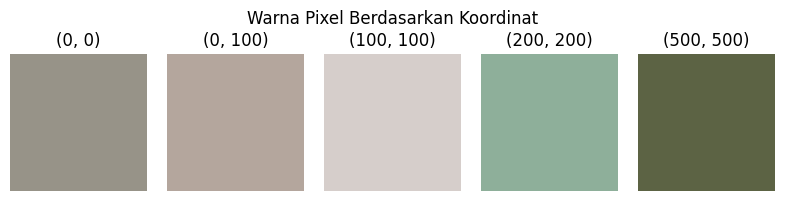

In [15]:
# ==========================================
# 9. MENENTUKAN BEBERAPA KOORDINAT PIXEL YANG AKAN DIANALISIS
# ==========================================

# Menentukan koordinat pixel yang akan dianalisis
koordinat_pixel = [
    (0, 0),
    (0, 100),
    (100, 100),
    (200, 200),
    (500, 500)
]

# Menyiapkan tempat untuk menyimpan hasil analisis
data_pixel = []

# Mengambil nilai RGB dari setiap koordinat pixel
for baris, kolom in koordinat_pixel:
    r, g, b = array_gambar[baris, kolom]

    # Menyimpan koordinat dan nilai RGB
    data_pixel.append({
        "Koordinat (Baris, Kolom)": f"({baris}, {kolom})",
        "Red (R)": int(r),
        "Green (G)": int(g),
        "Blue (B)": int(b),
        "Warna RGB": f"({r}, {g}, {b})"
    })

# Mengubah hasil analisis menjadi tabel
tabel_pixel = pd.DataFrame(data_pixel)

# Menampilkan tabel nilai RGB
display(tabel_pixel)

# Menampilkan warna dari setiap koordinat pixel
plt.figure(figsize=(8, 2))

for i, (baris, kolom) in enumerate(koordinat_pixel):

    # Mengambil kembali nilai RGB pixel
    r, g, b = array_gambar[baris, kolom]

    # Menampilkan warna pixel
    plt.subplot(1, len(koordinat_pixel), i + 1)
    plt.imshow([[[r, g, b]]])
    plt.title(f"({baris}, {kolom})")
    plt.axis("off")

# Memberikan judul dan merapikan tampilan
plt.suptitle("Warna Pixel Berdasarkan Koordinat")
plt.tight_layout()
plt.show()


### 9. Menentukan Beberapa Koordinat Pixel yang Akan Dianalisis

Bagian ini digunakan untuk mengambil nilai RGB dari beberapa koordinat pixel tertentu pada citra digital. Hasilnya ditampilkan dalam bentuk tabel dan visualisasi warna agar nilai angka RGB lebih mudah dipahami.

- `koordinat_pixel = [...]` → Menentukan lima koordinat pixel yang akan diperiksa, yaitu `(0, 0)`, `(0, 100)`, `(100, 100)`, `(200, 200)`, dan `(500, 500)`. Setiap koordinat menunjukkan posisi pixel berdasarkan baris dan kolom.

- `data_pixel = []` → Membuat list kosong untuk menampung hasil pengambilan koordinat dan nilai RGB setiap pixel.

- `for baris, kolom in koordinat_pixel:` → Melakukan perulangan untuk memproses setiap koordinat yang sudah ditentukan.

- `r, g, b = array_gambar[baris, kolom]` → Mengambil nilai warna Red (R), Green (G), dan Blue (B) dari pixel pada posisi baris dan kolom tersebut.

- `data_pixel.append({...})` → Menyimpan koordinat pixel, nilai R, G, B, dan gabungan nilai RGB ke dalam list. Fungsi `int()` digunakan untuk mengubah nilai warna menjadi bilangan bulat, sedangkan `f-string` digunakan untuk menyusun nilai menjadi teks yang mudah dibaca.

- `pd.DataFrame(data_pixel)` → Mengubah kumpulan data pixel menjadi tabel agar hasil analisis tersusun rapi.

- `display(tabel_pixel)` → Menampilkan tabel yang berisi koordinat dan nilai RGB setiap pixel.

- `plt.figure(figsize=(8, 2))` → Menyiapkan area gambar untuk menampilkan visualisasi warna dari pixel yang dipilih.

- `enumerate(koordinat_pixel)` → Melakukan perulangan sambil memberikan nomor urut pada setiap koordinat. Nomor ini digunakan untuk menentukan posisi visualisasi warna.

- `plt.subplot(1, len(koordinat_pixel), i + 1)` → Membagi area gambar menjadi satu baris dengan lima bagian, sehingga setiap pixel memiliki tempat visualisasi sendiri.

- `plt.imshow([[[r, g, b]]])` → Menampilkan warna berdasarkan nilai RGB pixel yang sedang dianalisis.

- `plt.title(f"({baris}, {kolom})")` → Memberikan label koordinat di atas setiap warna agar posisi pixel mudah dikenali.

- `plt.axis("off")` → Menyembunyikan sumbu agar visualisasi hanya berfokus pada warna pixel.

- `plt.suptitle("Warna Pixel Berdasarkan Koordinat")` → Memberikan judul utama pada visualisasi warna.

- `plt.tight_layout()` → Mengatur tata letak agar judul dan visualisasi tersusun lebih rapi.

- `plt.show()` → Menampilkan hasil visualisasi warna pixel.

**Hubungan antarbagian:**

Kode dimulai dengan menentukan koordinat pixel, kemudian mengambil nilai RGB dari setiap koordinat dan menyimpannya dalam tabel. Setelah itu, nilai RGB yang sama digunakan untuk menampilkan warna pixel secara visual. Dengan demikian, tabel memperlihatkan nilai warna dalam bentuk angka, sedangkan visualisasi membantu melihat warna yang dihasilkan oleh angka tersebut.

**Hasil analisis:**

Berdasarkan hasil pengujian, lima koordinat pixel berhasil dianalisis dan menghasilkan nilai RGB yang berbeda-beda. Perbedaan nilai tersebut menunjukkan bahwa setiap pixel dapat memiliki komposisi warna yang berbeda. Hasil ini membuktikan bahwa citra digital tersusun dari pixel yang masing-masing memiliki posisi dan nilai warna tertentu.


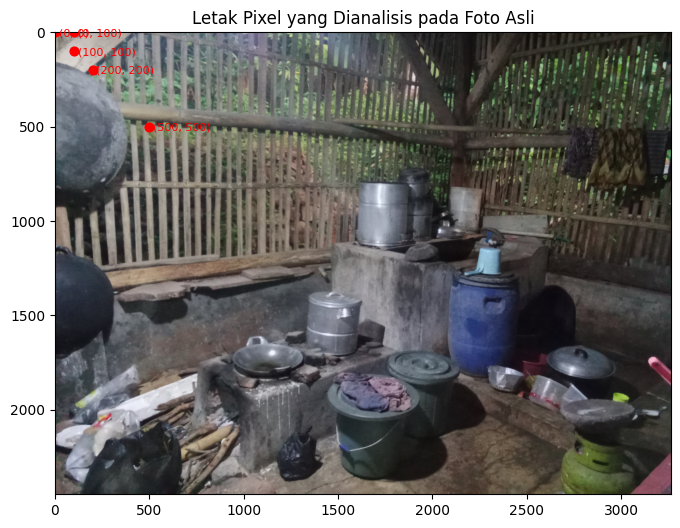

In [17]:
# ==========================================
# 10. MENANDAI LETAK PIXEL YANG DIANALISIS PADA FOTO ASLI
# ==========================================

# Menampilkan foto asli
plt.figure(figsize=(8, 6))
plt.imshow(gambar)

# Menandai posisi setiap pixel yang dianalisis
for baris, kolom in koordinat_pixel:

    # Menampilkan titik merah pada koordinat pixel
    plt.scatter(kolom, baris, color="red", s=40)

    # Menampilkan label koordinat pixel
    plt.text(
        kolom + 20,
        baris + 20,
        f"({baris}, {kolom})",
        color="red",
        fontsize=8
    )

# Memberikan judul pada gambar
plt.title("Letak Pixel yang Dianalisis pada Foto Asli")

# Menampilkan sumbu koordinat
plt.axis("on")

# Menampilkan hasil visualisasi
plt.show()

### 10. Menandai Letak Pixel yang Dianalisis pada Foto Asli

Bagian ini digunakan untuk menampilkan foto asli dan menandai posisi lima pixel yang telah ditentukan pada tahap sebelumnya. Setiap pixel ditandai dengan titik merah dan label koordinat agar lokasinya dapat diketahui secara langsung pada gambar.

- `plt.figure(figsize=(8, 6))` → Membuat area untuk menampilkan gambar dengan ukuran 8 × 6 inci.
- `plt.imshow(gambar)` → Menampilkan foto asli yang tersimpan dalam variabel `gambar`.
- `for baris, kolom in koordinat_pixel:` → Melakukan perulangan untuk mengambil setiap koordinat pixel yang telah ditentukan pada tahap 9.
- `plt.scatter(kolom, baris, color="red", s=40)` → Menandai posisi pixel menggunakan titik merah. `kolom` menentukan posisi horizontal, `baris` menentukan posisi vertikal, `color="red"` mengatur warna titik, dan `s=40` menentukan ukurannya.
- `plt.text(...)` → Menampilkan tulisan koordinat di dekat setiap titik merah. `kolom + 20` dan `baris + 20` mengatur posisi tulisan agar sedikit bergeser dari titik, `f"({baris}, {kolom})"` menampilkan koordinat, `color="red"` mengatur warna tulisan, dan `fontsize=8` menentukan ukuran huruf.
- `plt.title("Letak Pixel yang Dianalisis pada Foto Asli")` → Memberikan judul pada visualisasi.
- `plt.axis("on")` → Menampilkan sumbu koordinat pada gambar sehingga posisi pixel lebih mudah diamati.
- `plt.show()` → Menampilkan hasil akhir berupa foto asli dengan titik merah dan label koordinat.

**Hubungan antarbagian:**

Kode ini menggunakan variabel `koordinat_pixel` dari tahap 9. Pada tahap sebelumnya, koordinat tersebut digunakan untuk mengambil nilai RGB dan menampilkan warna setiap pixel. Pada tahap ini, koordinat yang sama ditandai pada foto asli agar posisi pixel dapat dilihat secara langsung.

**Hasil analisis:**

Berdasarkan hasil visualisasi, lima titik merah menunjukkan posisi pixel yang dianalisis pada foto asli. Setiap titik dilengkapi label koordinat, sehingga letak pixel dapat dibandingkan dengan nilai RGB yang diperoleh pada tahap sebelumnya. Hasil ini memperlihatkan bahwa setiap pixel memiliki posisi tertentu di dalam citra digital.


In [ ]:
# ==========================================
# 11. MENGUBAH GAMBAR MENJADI MATRIKS ANGKA
# ==========================================

matriks_pixel = array_gambar[0:5, 0:5]

print("Matriks pixel 5 × 5:")
print(matriks_pixel)

Matriks pixel 5 × 5:
[[[151 147 136]
  [145 141 130]
  [149 147 135]
  [154 152 140]
  [153 153 141]]

 [[152 148 137]
  [147 143 132]
  [147 145 133]
  [151 149 137]
  [150 150 138]]

 [[147 143 132]
  [145 141 130]
  [146 144 132]
  [150 148 136]
  [153 153 141]]

 [[149 145 134]
  [151 147 136]
  [150 148 136]
  [152 150 138]
  [153 153 141]]

 [[141 139 127]
  [146 144 132]
  [149 147 135]
  [152 150 138]
  [155 155 143]]]


## 11. Mengubah Gambar Menjadi Matriks Angka

Pada tahap ini, citra digital direpresentasikan dalam bentuk **matriks angka**. Karena ukuran gambar cukup besar, hanya sebagian matriks berukuran **5 × 5 pixel** yang ditampilkan agar hasilnya lebih mudah dibaca.

- `array_gambar[0:5, 0:5]` → mengambil 5 baris dan 5 kolom pertama dari citra.
- `matriks_pixel` → menyimpan bagian citra tersebut dalam bentuk matriks.
- `print(matriks_pixel)` → menampilkan nilai pixel dalam bentuk angka.

Setiap elemen pada matriks merupakan **satu pixel** yang memiliki tiga nilai, yaitu **R, G, dan B**.

Contohnya:

`[151 147 136]`

merupakan satu pixel dengan:
- **R = 151**
- **G = 147**
- **B = 136**

Hasil ini menunjukkan bahwa citra digital tidak hanya berupa gambar secara visual, tetapi juga dapat direpresentasikan sebagai **matriks yang berisi kumpulan angka RGB**. Seluruh gambar sebenarnya tersimpan dalam `array_gambar`, sedangkan pada tahap ini hanya sebagian matriks yang ditampilkan untuk mempermudah analisis.

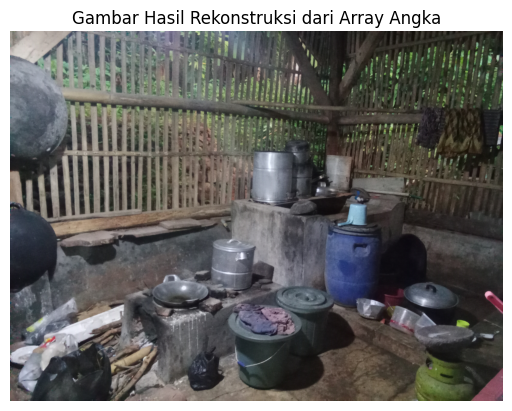

In [ ]:
# ==========================================
# 12. MEMBENTUK KEMBALI GAMBAR DARI ANGKA
# ==========================================

# Membentuk gambar dari array angka
gambar_rekonstruksi = Image.fromarray(array_gambar)

# Menampilkan gambar hasil rekonstruksi
plt.imshow(gambar_rekonstruksi)
plt.title("Gambar Hasil Rekonstruksi dari Array Angka")
plt.axis("off")
plt.show()

## 12. Membentuk Kembali Gambar dari Angka

Pada tahap ini, gambar dibentuk kembali menggunakan array angka yang telah diperoleh dari citra asli. Proses ini bertujuan untuk membuktikan bahwa susunan angka pixel dapat digunakan untuk menghasilkan gambar yang dapat dilihat kembali.

- `Image.fromarray(array_gambar)` → membentuk objek gambar dari array yang berisi nilai pixel.
- `gambar_rekonstruksi` → menyimpan gambar hasil rekonstruksi dari array angka.
- `plt.imshow(gambar_rekonstruksi)` → menampilkan gambar hasil rekonstruksi.
- `plt.title()` → memberikan judul pada gambar yang ditampilkan.
- `plt.axis("off")` → menyembunyikan sumbu koordinat agar tampilan gambar lebih rapi.
- `plt.show()` → menampilkan hasil visualisasi gambar.

Berdasarkan hasil yang ditampilkan, gambar hasil rekonstruksi terlihat sama seperti gambar asli. Hal ini menunjukkan bahwa data angka yang tersimpan dalam `array_gambar` dapat digunakan untuk membentuk kembali citra secara visual.

Dengan demikian, tahap ini memperkuat pembuktian bahwa **citra digital dapat direpresentasikan sebagai susunan angka yang menyimpan informasi setiap pixel**. Pada tahap berikutnya, kesamaan gambar asli dan hasil rekonstruksi akan diperiksa menggunakan Python agar pembuktiannya lebih akurat.

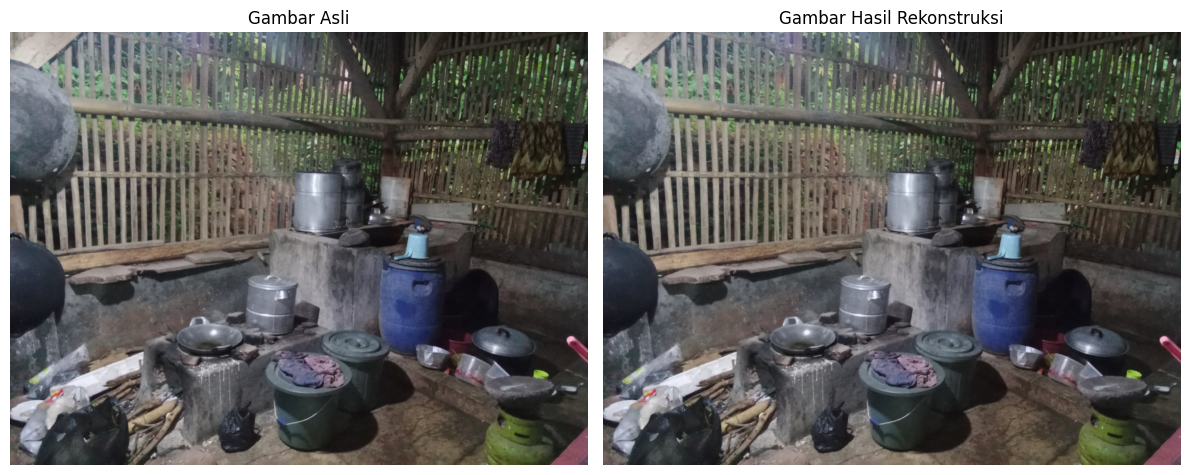

Bentuk array gambar asli        : (2448, 3264, 3)
Bentuk array hasil rekonstruksi : (2448, 3264, 3)
Apakah kedua gambar identik?    : True


In [ ]:
# ==========================================
# 13. MEMERIKSA KESAMAAN GAMBAR ASLI DAN HASIL REKONSTRUKSI
# ==========================================

# Membandingkan array angka asli dengan hasil rekonstruksi
array_rekonstruksi = np.array(gambar_rekonstruksi)
gambar_sama = np.array_equal(array_gambar, array_rekonstruksi)

# Menampilkan kedua gambar berdampingan
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(gambar)
plt.title("Gambar Asli")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gambar_rekonstruksi)
plt.title("Gambar Hasil Rekonstruksi")
plt.axis("off")

plt.tight_layout()
plt.show()

# Menampilkan hasil pemeriksaan kesamaan
print("Bentuk array gambar asli        :", array_gambar.shape)
print("Bentuk array hasil rekonstruksi :", array_rekonstruksi.shape)
print("Apakah kedua gambar identik?    :", gambar_sama)

## 13. Memeriksa Kesamaan Gambar Asli dan Hasil Rekonstruksi

Pada tahap ini, gambar asli dibandingkan dengan gambar hasil rekonstruksi untuk memeriksa apakah keduanya memiliki nilai pixel yang sama. Pemeriksaan dilakukan dengan membandingkan array angka dari gambar asli dan hasil rekonstruksi.

- `np.array(gambar_rekonstruksi)` → mengubah gambar hasil rekonstruksi menjadi array angka agar dapat dibandingkan dengan array gambar asli.
- `np.array_equal(array_gambar, array_rekonstruksi)` → membandingkan bentuk array dan seluruh nilai pixel pada kedua gambar.
- `plt.figure(figsize=(12, 5))` → mengatur ukuran area untuk menampilkan gambar.
- `plt.subplot(1, 2, 1)` → menyiapkan posisi gambar asli di sebelah kiri.
- `plt.subplot(1, 2, 2)` → menyiapkan posisi gambar hasil rekonstruksi di sebelah kanan.
- `plt.imshow()` → menampilkan masing-masing gambar.
- `plt.title()` → memberikan judul pada setiap gambar.
- `plt.axis("off")` → menyembunyikan sumbu koordinat agar tampilan lebih rapi.
- `plt.tight_layout()` → mengatur tata letak agar kedua gambar tersusun dengan baik.
- `plt.show()` → menampilkan kedua gambar secara berdampingan.
- `print()` → menampilkan ukuran array dan hasil pemeriksaan kesamaan gambar.

**Berdasarkan hasil pemeriksaan**, kedua gambar memiliki bentuk array yang sama, yaitu `(2448, 3264, 3)`. Hasil perbandingan menunjukkan nilai `True`, yang berarti seluruh nilai pixel pada array gambar asli dan array hasil rekonstruksi identik.

Hasil ini membuktikan bahwa gambar yang dibentuk kembali dari array angka memiliki data pixel yang sama dengan gambar asli. Dengan demikian, susunan angka pada citra digital dapat digunakan untuk merepresentasikan dan membentuk kembali gambar secara identik.

In [21]:
# ==========================================
# 14. KESIMPULAN HASIL ANALISIS CITRA DIGITAL
# ==========================================

# Menghitung jumlah pixel dan kanal warna
jumlah_pixel = array_gambar.shape[0] * array_gambar.shape[1]
jumlah_kanal = array_gambar.shape[2]

# Menampilkan ringkasan informasi citra
print("RINGKASAN HASIL ANALISIS CITRA DIGITAL")
print("Ukuran gambar       :", gambar.size)
print("Dimensi array       :", array_gambar.shape)
print("Jumlah pixel        :", f"{jumlah_pixel:,}".replace(",", "."))
print("Jumlah kanal warna  :", jumlah_kanal)
print("Kanal warna         : Red (R), Green (G), Blue (B)")
print("Tipe data pixel     :", array_gambar.dtype)
print("Hasil rekonstruksi  :", gambar_sama)

# Menampilkan ringkasan analisis koordinat pixel
print("\nRINGKASAN ANALISIS KOORDINAT PIXEL")
print("Jumlah pixel dianalisis :", len(koordinat_pixel))

for baris, kolom in koordinat_pixel:

    # Mengambil nilai RGB dari setiap koordinat pixel
    r, g, b = array_gambar[baris, kolom]

    # Menampilkan koordinat dan nilai RGB
    print(f"Koordinat ({baris}, {kolom}) : RGB ({r}, {g}, {b})")

# Menampilkan ringkasan informasi GPS
print("\nRINGKASAN METADATA GPS")
print("Status metadata GPS :", "Tersedia" if gps else "Tidak tersedia")

if gps and 2 in gps and 4 in gps:

    # Menampilkan koordinat GPS dalam bentuk desimal
    print("Latitude (Lintang)  :", f"{lintang:.6f}°")
    print("Longitude (Bujur)   :", f"{bujur:.6f}°")
    print("Koordinat desimal   :", f"{lintang:.6f}, {bujur:.6f}")
    print("Google Maps         :", link_maps)

else:
    print("Koordinat GPS tidak lengkap atau tidak tersedia.")

RINGKASAN HASIL ANALISIS CITRA DIGITAL
Ukuran gambar       : (3264, 2448)
Dimensi array       : (2448, 3264, 3)
Jumlah pixel        : 7.990.272
Jumlah kanal warna  : 3
Kanal warna         : Red (R), Green (G), Blue (B)
Tipe data pixel     : uint8
Hasil rekonstruksi  : True

RINGKASAN ANALISIS KOORDINAT PIXEL
Jumlah pixel dianalisis : 5
Koordinat (0, 0) : RGB (151, 147, 136)
Koordinat (0, 100) : RGB (180, 166, 157)
Koordinat (100, 100) : RGB (214, 206, 203)
Koordinat (200, 200) : RGB (142, 175, 154)
Koordinat (500, 500) : RGB (92, 99, 68)

RINGKASAN METADATA GPS
Status metadata GPS : Tersedia
Latitude (Lintang)  : -6.820098°
Longitude (Bujur)   : 108.554794°
Koordinat desimal   : -6.820098, 108.554794
Google Maps         : https://www.google.com/maps?q=-6.820097916666667,108.55479430555555


### 14. Kesimpulan Hasil Analisis Citra Digital

Bagian ini digunakan untuk merangkum hasil analisis citra digital yang telah dilakukan dari tahap awal hingga akhir. Kode menghitung jumlah pixel, menampilkan informasi kanal warna, merangkum nilai RGB dari lima koordinat pixel, memeriksa hasil rekonstruksi gambar, serta menampilkan informasi metadata GPS.

- `array_gambar.shape[0] * array_gambar.shape[1]` → Menghitung jumlah pixel berdasarkan jumlah baris dan kolom pada array gambar.
- `array_gambar.shape[2]` → Mengambil jumlah kanal warna pada gambar, yaitu tiga kanal RGB.
- `print()` → Menampilkan ringkasan informasi citra, seperti ukuran gambar, dimensi array, jumlah pixel, kanal warna, tipe data pixel, dan hasil rekonstruksi.
- `f"{jumlah_pixel:,}".replace(",", ".")` → Memformat jumlah pixel menggunakan tanda titik sebagai pemisah ribuan agar lebih mudah dibaca.
- `len(koordinat_pixel)` → Menghitung jumlah koordinat pixel yang dianalisis pada tahap 9.
- `for baris, kolom in koordinat_pixel:` → Melakukan perulangan untuk memeriksa setiap koordinat pixel yang telah ditentukan.
- `array_gambar[baris, kolom]` → Mengambil nilai RGB dari setiap koordinat pixel untuk ditampilkan kembali dalam ringkasan.
- `if gps and 2 in gps and 4 in gps:` → Memeriksa apakah metadata GPS tersedia dan memiliki data lintang serta bujur yang diperlukan.
- `f"{lintang:.6f}°"` dan `f"{bujur:.6f}°"` → Menampilkan koordinat lintang dan bujur dengan enam angka di belakang koma.
- `link_maps` → Menampilkan tautan Google Maps berdasarkan koordinat GPS yang telah dikonversi ke bentuk desimal.
- `else:` → Menampilkan pesan bahwa koordinat GPS tidak lengkap atau tidak tersedia apabila persyaratan data GPS tidak terpenuhi.
- Bagian **KESIMPULAN AKHIR** → Menampilkan rangkuman hasil utama mengenai representasi pixel, nilai RGB, penandaan posisi pixel pada foto asli, rekonstruksi citra, dan pemeriksaan metadata GPS.

**Hasil analisis:**

Berdasarkan output yang diperoleh, gambar memiliki ukuran 3264 × 2448 pixel dengan total 7.990.272 pixel. Gambar menggunakan tiga kanal warna, yaitu Red (R), Green (G), dan Blue (B), dengan tipe data `uint8`.

Analisis pada lima koordinat pixel menghasilkan nilai RGB yang berbeda-beda. Posisi kelima pixel tersebut juga telah ditandai pada foto asli menggunakan titik merah, sehingga nilai warna dapat dikaitkan dengan lokasi pixel pada gambar.

Pemeriksaan rekonstruksi menghasilkan nilai `True`, yang menunjukkan bahwa array hasil rekonstruksi identik dengan array gambar asli berdasarkan pemeriksaan kesamaan yang dilakukan. Selain itu, metadata GPS berhasil dibaca dan menghasilkan koordinat lintang -6.820098° serta bujur 108.554794° yang dapat digunakan untuk membuka lokasi melalui Google Maps.

**Kesimpulan akhir:**

Dari seluruh tahapan analisis, dapat disimpulkan bahwa citra digital dapat direpresentasikan sebagai kumpulan pixel dalam bentuk array numerik. Setiap pixel memiliki posisi dan nilai RGB yang menentukan warna, sedangkan visualisasi koordinat membantu menunjukkan letaknya pada foto asli. Proses rekonstruksi membuktikan bahwa data numerik dapat digunakan untuk membentuk kembali citra yang identik dengan gambar asli. Sementara itu, metadata GPS memberikan informasi tambahan berupa koordinat lokasi yang tersimpan pada gambar.